# Topic model walkthrough

This notebook runs the Headline Radar topic model one step at a time:

1. Load article texts from the database.
2. Build the text embedder.
3. Fit the topic model.
4. Look at the topics, the fit diagnostics, and example texts.
5. Give a few topics readable names.
6. Plot the topic hierarchy and build the topic explorer.
7. Label new texts that the model has never seen.
8. Join the topics back onto the articles table.

Run `python -m de.load_news` first so the database has articles.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from models import TextEmbedder, TopicExplorer, TopicJoiner, TopicModel, TopicPipeline

pd.set_option("display.max_colwidth", 120)
OUTPUT_FOLDER = PROJECT_ROOT / "outputs" / "notebook"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

/workspace/headline-radar/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load article texts

Each text is the headline, plus the description when the source has one. GDELT rows only have a headline.

In [2]:
pipeline = TopicPipeline(database_path=PROJECT_ROOT / "data" / "headline_radar.db")
articles = pipeline.load_articles()
texts = articles["text"].tolist()

print(f"{len(texts):,} articles, {articles['text'].nunique():,} unique texts")
articles[["source_type", "source", "text"]].sample(5, random_state=1)

41,277 articles, 26,748 unique texts


,source_type,source,text
7030,gdelt,worcesternews.co.uk,Sales of gaming consoles 'surge' ahead of GTA VI release
4512,gdelt,freemalaysiatoday.com,Russian flight lands in Turkey after bomb threat hoax
33450,gdelt,nzcity.co.nz,The Port of Auckland's prepping for increased cruises with a new terminal - 19-Nov-2026
10432,gdelt,gator995.com,Chris Janson Gets Vocal About Morgan Wallen's Constant CMA Snubs [EXCLUSIVE]
21196,gdelt,wn.com,Hezbollah chief offers condolences on passing of Ayatollah Vahid Khorasani


## 2. Build the embedder

`TextEmbedder` turns each text into a 384-number vector with MiniLM. Similar texts get similar vectors.

In [3]:
embedder = TextEmbedder()
sample = embedder.encode(["Stocks fall as rates rise", "Markets drop on higher interest rates", "Local team wins the final"])
print("Embedding size:", sample.shape[1])
print("Similarity of the first text to the other two:", (sample[0] @ sample[1:].T).round(2))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13211.82it/s]

Embedding size: 384
Similarity of the first text to the other two: [ 0.66 -0.08]


## 3. Fit the topic model

`min_topic_size` is the smallest number of texts a topic can have. Texts that do not fit any topic get `-1`.

In [4]:
model = TopicModel(min_topic_size=30, embedder=embedder)
topic_ids = model.fit_transform(texts)
articles["topic_id"] = topic_ids

topic_count = sum(1 for topic in model.topic_ids_ if topic >= 0)
outlier_share = (articles["topic_id"] == TopicModel.OUTLIER_TOPIC).mean()
print(f"{topic_count} topics, {outlier_share:.0%} outliers")

Encoded 6,400/26,748 texts


Encoded 12,800/26,748 texts


Encoded 19,200/26,748 texts


Encoded 25,600/26,748 texts


Encoded 26,748/26,748 texts


283 topics, 40% outliers


## 4. Topics and diagnostics

`get_topic_info` has one row per topic. Topic 0 is the largest.

In [5]:
topic_info = model.get_topic_info()
topic_info[["topic_id", "document_count", "topic_name", "needs_review"]].head(15)

,topic_id,document_count,topic_name,needs_review
0,-1,16523,-1: Outliers (no topic),False
1,0,1089,"0: man, police, arrested, charged",False
2,1,791,"1: ghana, ghanamma com, ghanamma, nigeria",False
3,2,589,"2: 2027 gen, surpass baby, set surpass, roles 2027",False
4,3,493,"3: ai, ai agents, microsoft, agents",False
5,4,443,"4: christmas, lights, holiday, tree",False
6,5,430,"5: music, fm, concert, hits",False
7,6,408,"6: school, education, college, schools",False
8,7,384,"7: gta, vi, grand theft, theft auto",False
9,8,353,"8: cancer, health, brain, glp",False


The diagnostics compare the cluster sizes from HDBSCAN with the sizes after identical texts were given one shared topic. Clusters that fell below `min_topic_size` are not kept.

In [6]:
diagnostics = model.get_fit_diagnostics()
print("Clusters from HDBSCAN:", (diagnostics["cluster_id"] >= 0).sum())
print("Clusters kept as topics:", diagnostics["kept"].sum())
print("Texts moved to outliers after the vote:", model.pruned_document_count_)
diagnostics.head(10)

Clusters from HDBSCAN: 341
Clusters kept as topics: 283
Texts moved to outliers after the vote: 135


,cluster_id,hdbscan_count,count_after_vote,kept,topic_id
0,-1,16440,16388,False,-1
1,0,39,0,False,-1
2,1,48,85,True,79
3,2,62,0,False,-1
4,3,39,39,True,210
5,4,43,82,True,87
6,5,59,59,True,127
7,6,53,53,True,145
8,7,47,0,False,-1
9,8,65,1,False,-1


## 5. Example texts

Keywords and example texts for the three largest topics.

In [7]:
for topic in range(3):
    words = [word for word, _ in model.get_topic_words(topic)]
    print(f"Topic {topic}: {', '.join(words)}")
    for example in model.get_example_documents()[topic]:
        print("   -", example[:150])
    print()

Topic 0: man, police, arrested, charged, shooting, accused, murder, man arrested, charges, arrest
   - Former Gallatin County Undersheriff arrested on child sex abuse charges
   - Second Suspect Arrested in Osage County Home Invasion Case
   - Man accused of killing Enosburgh woman pleads guilty

Topic 1: ghana, ghanamma com, ghanamma, nigeria, uganda, election, tinubu, africa, ruto, com
   - Latest News In Nigeria, Nigeria News Today, Your Online Nigerian Newspaper
   - No Serious Rift Between Tinubu, Makinde - Oyo Monarch - Latest News In Nigeria, Nigeria News Today, Your Online Nigerian Newspaper
   - 'My visit about Nigeria's development' - Obi debunks US congress endorsement claims - Latest News In Nigeria, Nigeria News Today, Your Online Nigerian

Topic 2: 2027 gen, surpass baby, set surpass, roles 2027, management roles, gen set, boomers management, baby boomers, boomers, roles
   - Gen Z Set To Surpass Baby Boomers In Management Roles By 2027



## 6. Custom labels

Keyword names are a good start. After reading the examples, give the topics short names. Change these to match your own fit.

In [8]:
labels = {
    0: f"Topic 0 ({model.get_topic_words(0)[0][0]})",
    1: f"Topic 1 ({model.get_topic_words(1)[0][0]})",
}
model.set_topic_labels(labels)
model.get_topic_info()[["topic_id", "document_count", "topic_name"]].head(4)

,topic_id,document_count,topic_name
0,-1,16523,-1: Outliers (no topic)
1,0,1089,0: Topic 0 (man)
2,1,791,1: Topic 1 (ghana)
3,2,589,"2: 2027 gen, surpass baby, set surpass, roles 2027"


## 7. Topic hierarchy

Topics close together on the tree use similar words. Hover over a merge point to see the shared keywords. The chart is saved as HTML and PNG in `outputs/notebook/`.

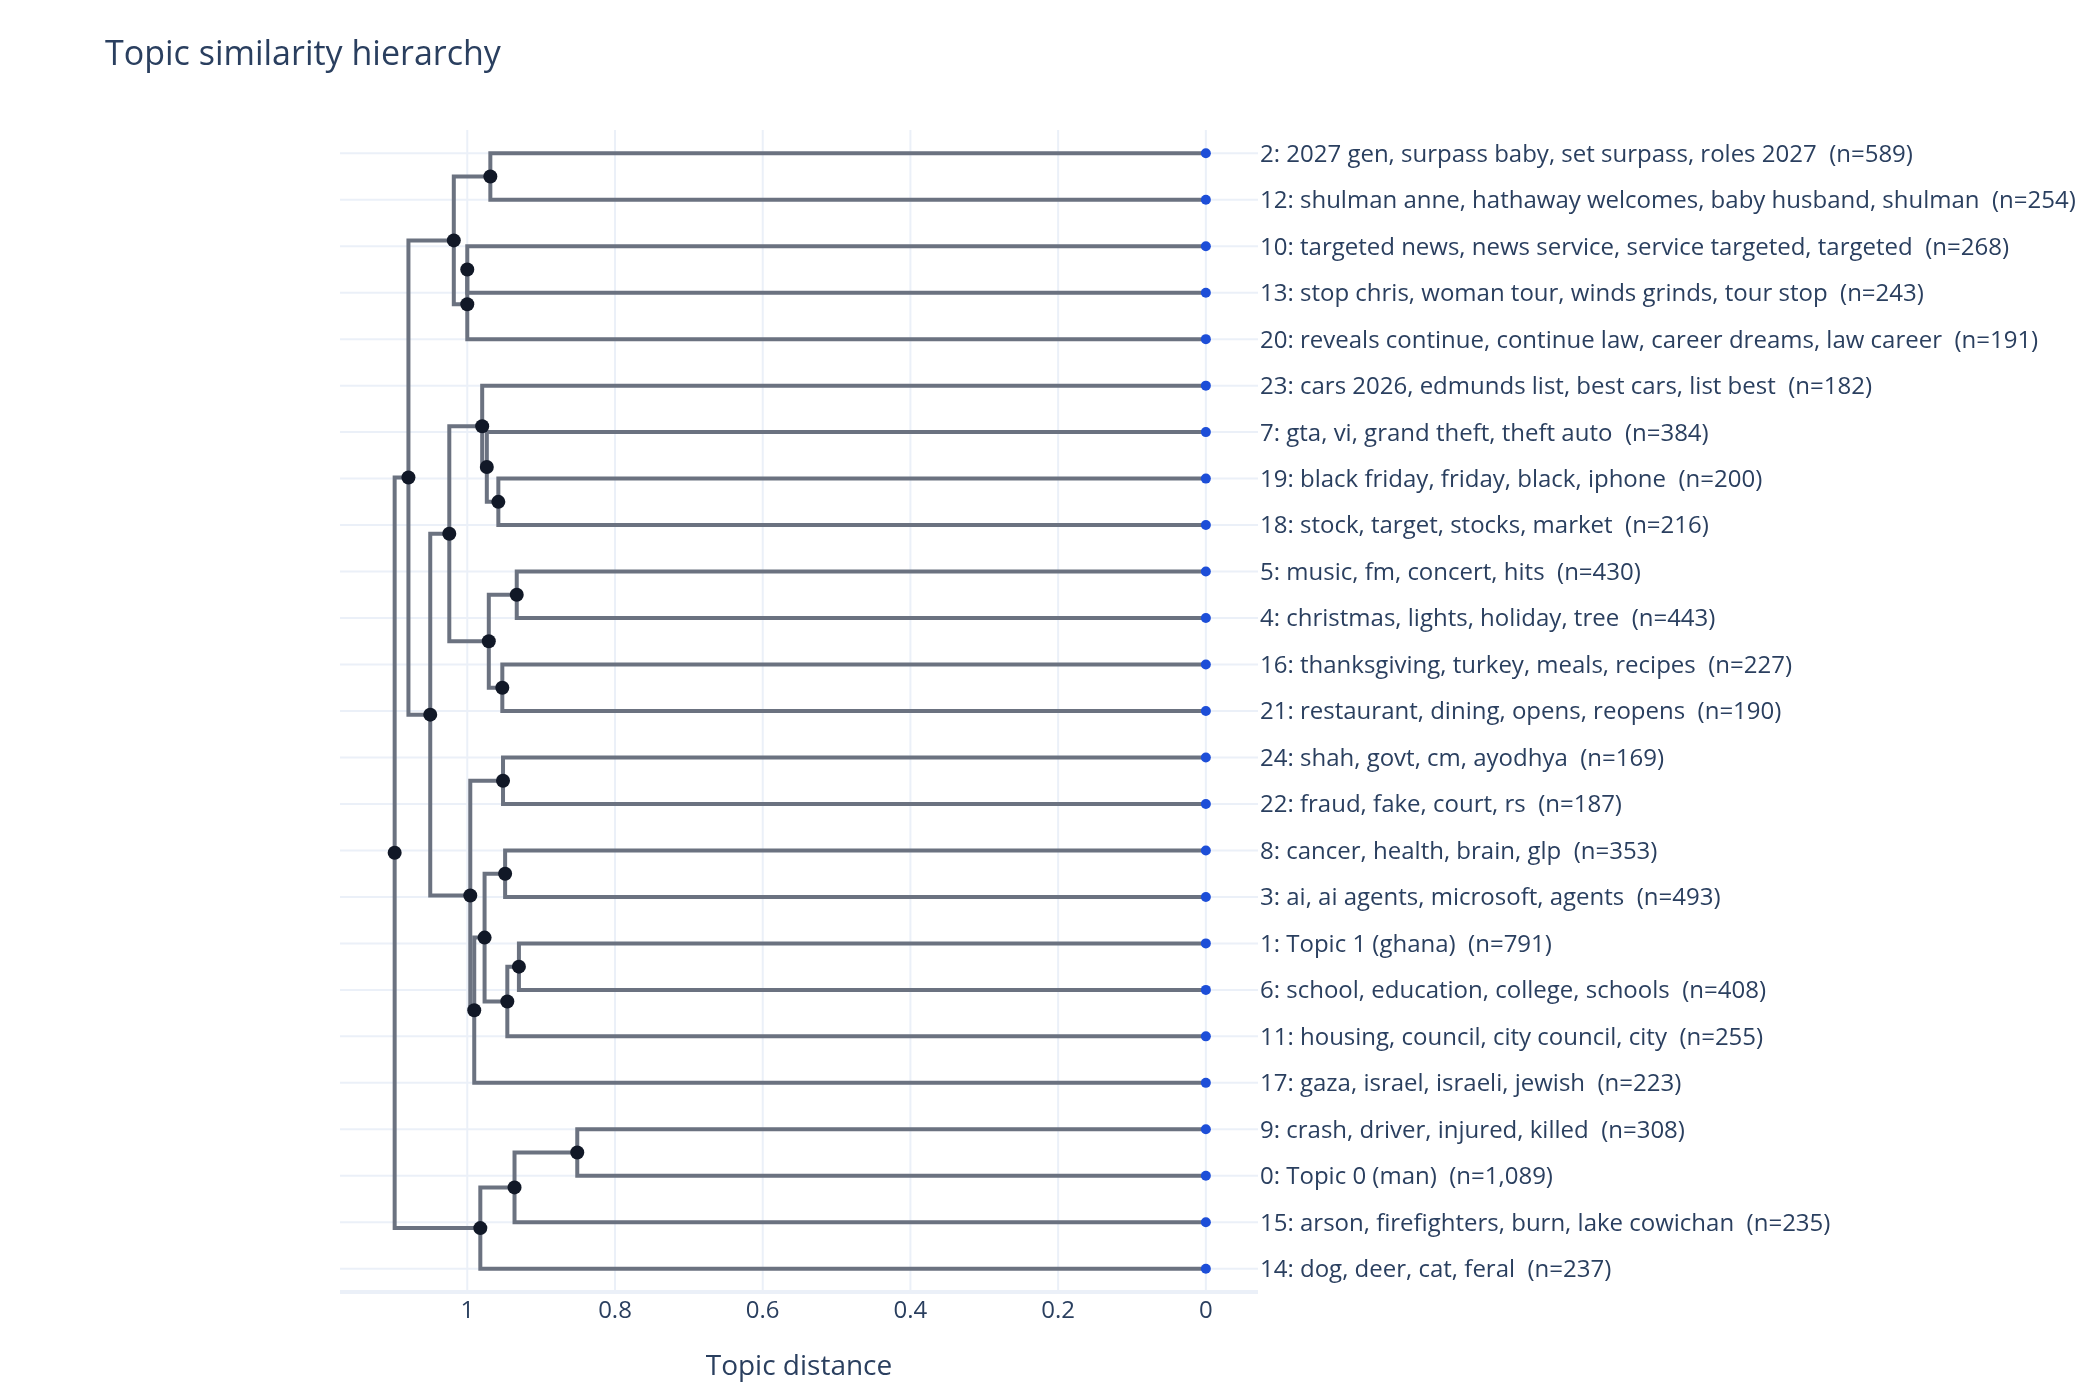

In [9]:
hierarchy = model.visualize_hierarchy(top_n_topics=25)
hierarchy.write_html(OUTPUT_FOLDER / "topic_hierarchy.html", include_plotlyjs=True)
hierarchy.write_image(OUTPUT_FOLDER / "topic_hierarchy.png", scale=2)
display(Image(filename=str(OUTPUT_FOLDER / "topic_hierarchy.png"), width=900))

## 8. Topic explorer

The explorer is a single HTML file with a 2D map of every unique text colored by topic, a bar chart of topic sizes, and a table of every topic. Open it in a browser.

In [10]:
explorer = TopicExplorer(model)
explorer_path = explorer.save(OUTPUT_FOLDER / "topic_explorer.html", texts, topic_ids)
print("Saved", explorer_path.relative_to(PROJECT_ROOT))

Saved outputs/notebook/topic_explorer.html


## 9. Label new texts

`transform_with_status` says how each topic was found:

- `seen`: the text was in the fit data, so it keeps its fitted topic.
- `new`: the topic was predicted with HDBSCAN.
- `blank`: the text was empty, so it gets `-2`.

In [11]:
new_texts = [
    texts[0],
    "Federal Reserve signals another interest rate cut as inflation cools",
    "Police arrest man after downtown crash",
    "Nvidia shares climb ahead of earnings",
    "",
]
results = model.transform_with_status(new_texts)
results["topic_name"] = [model.topic_name(topic) if topic != TopicModel.BLANK_TOPIC else "Blank text" for topic in results["topic_id"]]
results

,text,topic_id,status,topic_name
0,"Nowhere Bar provides great tunes, odd views",5,seen,"music, fm, concert, hits"
1,Federal Reserve signals another interest rate cut as inflation cools,184,new,"worries mount, rates needed, inflation worries, higher rates"
2,Police arrest man after downtown crash,0,new,Topic 0 (man)
3,Nvidia shares climb ahead of earnings,209,new,"nvidia, earnings, nvidia earnings, earnings report"
4,,-2,blank,Blank text


## 10. Join topics back to a table

`TopicJoiner` adds a `topic_id` column to any DataFrame by exact text match. It never adds rows, gives blank text `-2`, and raises an error if a text is missing from the lookup, which means the model needs a refit.

In [12]:
fit_topics = pd.DataFrame({"text": texts, "topic_id": topic_ids})
joiner = TopicJoiner(text_column="text")
labeled = joiner.join(articles.drop(columns="topic_id"), fit_topics)

print("Rows before:", len(articles), "Rows after:", len(labeled))
labeled["topic_name"] = [model.topic_name(topic) for topic in labeled["topic_id"]]
labeled[["source", "topic_id", "topic_name"]].head()

Rows before: 41277 Rows after: 41277


,source,topic_id,topic_name
0,redandblack.com,5,"music, fm, concert, hits"
1,nassauweekly.com,-1,Outliers (no topic)
2,antonyloewenstein.com,-1,Outliers (no topic)
3,antonyloewenstein.com,-1,Outliers (no topic)
4,cruiselawnews.com,151,"cruise, cruises, riverboat, orleans"


## 11. Save and reload

`save` stores the model and the embedder in one folder. `load` gives back the same answers.

In [13]:
model_folder = PROJECT_ROOT / "data" / "topic_model"
model.save(model_folder)
reloaded = TopicModel.load(model_folder)
print("Same topics after reload:", (reloaded.transform(new_texts) == model.transform(new_texts)).all())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  8.24it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  8.17it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13390.78it/s]

Same topics after reload: True
